# Experiment 8: Multi-Agent Task Allocation and Coordination

**Name:** Aditya Gaur  
**Roll Number:** U23AI095  
**College:** Sardar Vallabhbhai National Institute of Technology (SVNIT), Surat  
**Course:** Intelligent Multi-Agent and Expert Systems

## Aim
To implement a multi-agent task-allocation system using **Partial Global Planning (PGP)** and the **Contract Net Protocol (CNP)**.

## What this notebook covers
1. Create one Manager Agent and three Delivery Agents, with eight delivery tasks and agent-specific cost/time estimates.
2. Create local plans, detect a shared-location/resource conflict, and reschedule one plan to resolve it.
3. Demonstrate the CNP stages: task announcement, bidding, bid comparison, agent selection, and task assignment.
4. Allocate every task automatically and calculate total cost and time.
5. Change selected bid values, rerun the allocation, compare outcomes, and visualize per-agent totals.

The assignment gives the required activities but does not prescribe delivery-task names, bid values, or a particular bid-scoring formula. The example data and the simple scoring rule below are stated explicitly so the experiment is reproducible.

## 1. Model and assumptions

- The system has **one manager** and **three delivery agents**.
- There are eight delivery tasks, exceeding the minimum of six. Every task has a separate cost and time bid from each delivery agent.
- For this demonstration, each bid is represented by a cost estimate and a time estimate. To rank offers consistently, the manager uses the simple teaching score

  \[
  \text{bid score} = \text{cost} + \text{time}
  \]

  The smallest score wins. This is a deliberately simple heuristic for the lab, not a universal CNP rule. Cost and time are still reported and summed separately; the combined score is used only to compare competing offers.
- PGP is demonstrated by combining local plans into a shared view, identifying simultaneous use of the same location or resource, and revising one agent's plan. This is a compact simulation of the coordination idea, not a full industrial scheduling system.
- In the allocation exercise, tasks are awarded independently using their bids. For overall time, the notebook reports both the sum of selected task durations (total agent-time) and an estimated parallel completion time (the maximum accumulated workload of any one agent, assuming each agent performs its allocated tasks sequentially).

## 2. Import the required libraries

In [1]:
import copy
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 42)

## 3. Set up the manager, delivery agents, tasks, and bid data

In [2]:
class DeliveryAgent:
    """A delivery agent that returns its cost and time estimate for a task."""
    def __init__(self, name, bid_data):
        self.name = name
        self.bid_data = bid_data

    def submit_bid(self, task_id):
        offer = self.bid_data[task_id][self.name]
        return {
            "Task ID": task_id,
            "Agent": self.name,
            "Cost": offer["cost"],
            "Time (min)": offer["time"],
            "Bid Score": offer["cost"] + offer["time"]
        }


class ManagerAgent:
    """Announces tasks, compares bids, and assigns each task to a winner."""
    def __init__(self, name="Manager Agent"):
        self.name = name

    @staticmethod
    def select_winner(bids):
        # Cost + time is the simple comparison score used in this example.
        # Tie-breakers make the result deterministic if scores are equal.
        return min(bids, key=lambda bid: (
            bid["Bid Score"], bid["Cost"], bid["Time (min)"], bid["Agent"]
        ))

    def allocate(self, tasks, agents, show_trace=False):
        allocations = []
        bid_rows = []
        process_rows = []

        for task in tasks:
            task_id = task["Task ID"]
            task_name = task["Task"]
            process_rows.append({"Task ID": task_id, "Stage": "Task Announcement", "Details": f"{self.name} announces: {task_name}"})
            if show_trace:
                print(f"\nTASK ANNOUNCEMENT: {task_id} - {task_name}")
                print("BIDDING:")

            bids = []
            for agent in agents:
                bid = agent.submit_bid(task_id)
                bids.append(bid)
                bid_rows.append({**bid, "Task": task_name})
                process_rows.append({
                    "Task ID": task_id,
                    "Stage": "Bidding",
                    "Details": f"{agent.name} offers cost={bid['Cost']}, time={bid['Time (min)']} min, score={bid['Bid Score']}"
                })
                if show_trace:
                    print(f"  {agent.name}: cost={bid['Cost']}, time={bid['Time (min)']} min, score={bid['Bid Score']}")

            if show_trace:
                print("BID COMPARISON (lower score wins):")
                display(pd.DataFrame(bids)[["Agent", "Cost", "Time (min)", "Bid Score"]])

            winner = self.select_winner(bids)
            process_rows.append({
                "Task ID": task_id,
                "Stage": "Bid Comparison",
                "Details": "Compared all submitted bid scores; the smallest score is selected."
            })
            process_rows.append({
                "Task ID": task_id,
                "Stage": "Agent Selection",
                "Details": f"{winner['Agent']} selected with score {winner['Bid Score']}"
            })
            process_rows.append({
                "Task ID": task_id,
                "Stage": "Task Assignment",
                "Details": f"{task_id} assigned to {winner['Agent']}"
            })

            allocation = {
                "Task ID": task_id,
                "Task": task_name,
                "Selected Agent": winner["Agent"],
                "Cost": winner["Cost"],
                "Time (min)": winner["Time (min)"],
                "Bid Score": winner["Bid Score"]
            }
            allocations.append(allocation)
            if show_trace:
                print(f"AGENT SELECTION: {winner['Agent']}")
                print(f"TASK ASSIGNMENT: {task_id} is assigned to {winner['Agent']}\n")

        return (
            pd.DataFrame(allocations),
            pd.DataFrame(bid_rows),
            pd.DataFrame(process_rows)
        )


manager = ManagerAgent()
agent_names = ["Delivery Agent A", "Delivery Agent B", "Delivery Agent C"]

tasks = [
    {"Task ID": "T1", "Task": "Documents to North Gate"},
    {"Task ID": "T2", "Task": "Grocery parcel to Library"},
    {"Task ID": "T3", "Task": "Medicine to Clinic"},
    {"Task ID": "T4", "Task": "Laptop to Hostel"},
    {"Task ID": "T5", "Task": "Supplies to Admin Block"},
    {"Task ID": "T6", "Task": "Lab samples to Medical Centre"},
    {"Task ID": "T7", "Task": "Books to Central Library"},
    {"Task ID": "T8", "Task": "Urgent envelope to Registrar"},
]

task_catalog = pd.DataFrame(tasks)
display(task_catalog)
print(f"System setup: 1 manager ({manager.name}), {len(agent_names)} delivery agents, and {len(tasks)} delivery tasks.")

,Task ID,Task
0,T1,Documents to North Gate
1,T2,Grocery parcel to Library
2,T3,Medicine to Clinic
3,T4,Laptop to Hostel
4,T5,Supplies to Admin Block
5,T6,Lab samples to Medical Centre
6,T7,Books to Central Library
7,T8,Urgent envelope to Registrar


System setup: 1 manager (Manager Agent), 3 delivery agents, and 8 delivery tasks.


In [3]:
# Each agent gives a different estimated cost and duration for every delivery task.
# Cost is expressed in illustrative cost units; time is in minutes.
base_bid_data = {
    "T1": {
        "Delivery Agent A": {"cost": 120, "time": 25},
        "Delivery Agent B": {"cost": 110, "time": 30},
        "Delivery Agent C": {"cost": 130, "time": 28},
    },
    "T2": {
        "Delivery Agent A": {"cost": 90, "time": 20},
        "Delivery Agent B": {"cost": 105, "time": 24},
        "Delivery Agent C": {"cost": 85, "time": 23},
    },
    "T3": {
        "Delivery Agent A": {"cost": 140, "time": 35},
        "Delivery Agent B": {"cost": 135, "time": 32},
        "Delivery Agent C": {"cost": 150, "time": 30},
    },
    "T4": {
        "Delivery Agent A": {"cost": 100, "time": 28},
        "Delivery Agent B": {"cost": 125, "time": 26},
        "Delivery Agent C": {"cost": 110, "time": 22},
    },
    "T5": {
        "Delivery Agent A": {"cost": 115, "time": 27},
        "Delivery Agent B": {"cost": 95, "time": 31},
        "Delivery Agent C": {"cost": 102, "time": 25},
    },
    "T6": {
        "Delivery Agent A": {"cost": 160, "time": 40},
        "Delivery Agent B": {"cost": 155, "time": 38},
        "Delivery Agent C": {"cost": 140, "time": 36},
    },
    "T7": {
        "Delivery Agent A": {"cost": 80, "time": 18},
        "Delivery Agent B": {"cost": 90, "time": 20},
        "Delivery Agent C": {"cost": 88, "time": 16},
    },
    "T8": {
        "Delivery Agent A": {"cost": 130, "time": 30},
        "Delivery Agent B": {"cost": 145, "time": 28},
        "Delivery Agent C": {"cost": 125, "time": 32},
    },
}

agents = [DeliveryAgent(name, base_bid_data) for name in agent_names]

# Show every possible bid so that the agent-specific cost/time differences are visible.
all_offers = []
for task in tasks:
    for agent in agents:
        all_offers.append(agent.submit_bid(task["Task ID"]))

bid_matrix = pd.DataFrame(all_offers)
bid_matrix.insert(1, "Task", bid_matrix["Task ID"].map({t["Task ID"]: t["Task"] for t in tasks}))
display(bid_matrix[["Task ID", "Task", "Agent", "Cost", "Time (min)", "Bid Score"]])

,Task ID,Task,Agent,Cost,Time (min),Bid Score
0,T1,Documents to North Gate,Delivery Agent A,120,25,145
1,T1,Documents to North Gate,Delivery Agent B,110,30,140
2,T1,Documents to North Gate,Delivery Agent C,130,28,158
3,T2,Grocery parcel to Library,Delivery Agent A,90,20,110
4,T2,Grocery parcel to Library,Delivery Agent B,105,24,129
5,T2,Grocery parcel to Library,Delivery Agent C,85,23,108
6,T3,Medicine to Clinic,Delivery Agent A,140,35,175
7,T3,Medicine to Clinic,Delivery Agent B,135,32,167
8,T3,Medicine to Clinic,Delivery Agent C,150,30,180
9,T4,Laptop to Hostel,Delivery Agent A,100,28,128


## 4. PGP coordination: create local plans and resolve a conflict

Each delivery agent first prepares a local plan. The manager then views the plans together. A conflict occurs when two different agents are scheduled at the **same time** and use either the same location or the same resource. The manager resolves the demonstrated conflict by moving one of the conflicting visits to the first available candidate time.

In [4]:
local_plans = pd.DataFrame([
    {"Agent": "Delivery Agent A", "Task": "Collect documents", "Location": "Shared Distribution Hub", "Resource": "Loading Dock 1", "Time Slot": "09:00"},
    {"Agent": "Delivery Agent B", "Task": "Collect grocery parcel", "Location": "Shared Distribution Hub", "Resource": "Loading Dock 1", "Time Slot": "09:00"},
    {"Agent": "Delivery Agent C", "Task": "Pick up medical package", "Location": "Medical Centre", "Resource": "Medical Bay", "Time Slot": "09:15"},
])

def detect_plan_conflicts(plans):
    """Return every pair scheduled together at the same location or resource."""
    conflicts = []
    rows = plans.reset_index(drop=True)
    for i in range(len(rows)):
        for j in range(i + 1, len(rows)):
            first = rows.iloc[i]
            second = rows.iloc[j]
            if first["Agent"] == second["Agent"] or first["Time Slot"] != second["Time Slot"]:
                continue
            same_location = first["Location"] == second["Location"]
            same_resource = first["Resource"] == second["Resource"]
            if same_location or same_resource:
                reasons = []
                if same_location:
                    reasons.append("same location")
                if same_resource:
                    reasons.append("same resource")
                conflicts.append({
                    "Agent 1": first["Agent"],
                    "Agent 2": second["Agent"],
                    "Time Slot": first["Time Slot"],
                    "Location": first["Location"] if same_location else f"{first['Location']} / {second['Location']}",
                    "Resource": first["Resource"] if same_resource else f"{first['Resource']} / {second['Resource']}",
                    "Reason": " and ".join(reasons)
                })
    return pd.DataFrame(conflicts, columns=["Agent 1", "Agent 2", "Time Slot", "Location", "Resource", "Reason"])

print("Initial local plans:")
display(local_plans)

conflicts_before = detect_plan_conflicts(local_plans)
print("Conflicts found before coordination:")
display(conflicts_before if not conflicts_before.empty else pd.DataFrame({"Result": ["No conflicts found"]}))

Initial local plans:


,Agent,Task,Location,Resource,Time Slot
0,Delivery Agent A,Collect documents,Shared Distribution Hub,Loading Dock 1,09:00
1,Delivery Agent B,Collect grocery parcel,Shared Distribution Hub,Loading Dock 1,09:00
2,Delivery Agent C,Pick up medical package,Medical Centre,Medical Bay,09:15


Conflicts found before coordination:


,Agent 1,Agent 2,Time Slot,Location,Resource,Reason
0,Delivery Agent A,Delivery Agent B,09:00,Shared Distribution Hub,Loading Dock 1,same location and same resource


In [5]:
def resolve_plan_conflicts(plans, candidate_slots):
    """Reschedule a conflicting agent visit until the combined plans are conflict-free."""
    coordinated = plans.copy(deep=True).reset_index(drop=True)
    changes = []

    # A limit protects against an endlessly repeating schedule if no slot is available.
    for _ in range(20):
        conflicts = detect_plan_conflicts(coordinated)
        if conflicts.empty:
            return coordinated, pd.DataFrame(changes, columns=["Agent", "Task", "Old Time Slot", "New Time Slot", "Reason"])

        first_conflict = conflicts.iloc[0]
        # Keep Agent 1's local plan and revise Agent 2's plan for this example.
        move_agent = first_conflict["Agent 2"]
        row_index = coordinated.index[coordinated["Agent"] == move_agent][0]
        old_slot = coordinated.at[row_index, "Time Slot"]
        revised = False

        for slot in candidate_slots:
            if slot == old_slot:
                continue
            trial = coordinated.copy(deep=True)
            trial.at[row_index, "Time Slot"] = slot
            trial_conflicts = detect_plan_conflicts(trial)
            # Accept a slot only if the full combined plan has no remaining conflict.
            if trial_conflicts.empty:
                reason = f"Moved because {first_conflict['Reason']} occurred at {old_slot}."
                changes.append({
                    "Agent": move_agent,
                    "Task": coordinated.at[row_index, "Task"],
                    "Old Time Slot": old_slot,
                    "New Time Slot": slot,
                    "Reason": reason
                })
                coordinated = trial
                revised = True
                break

        if not revised:
            raise RuntimeError("No conflict-free time slot was available for the current plan.")

    raise RuntimeError("The plans could not be coordinated within the allowed number of revisions.")

coordinated_plans, plan_changes = resolve_plan_conflicts(
    local_plans,
    candidate_slots=["09:00", "09:15", "09:30", "09:45", "10:00"]
)

print("Plan revision made by the manager:")
display(plan_changes)
print("Coordinated global plan:")
display(coordinated_plans)
print("Conflicts after coordination:")
conflicts_after = detect_plan_conflicts(coordinated_plans)
display(conflicts_after if not conflicts_after.empty else pd.DataFrame({"Result": ["No conflicts remain"]}))

Plan revision made by the manager:


,Agent,Task,Old Time Slot,New Time Slot,Reason
0,Delivery Agent B,Collect grocery parcel,09:00,09:15,Moved because same location and same r...


Coordinated global plan:


,Agent,Task,Location,Resource,Time Slot
0,Delivery Agent A,Collect documents,Shared Distribution Hub,Loading Dock 1,09:00
1,Delivery Agent B,Collect grocery parcel,Shared Distribution Hub,Loading Dock 1,09:15
2,Delivery Agent C,Pick up medical package,Medical Centre,Medical Bay,09:15


Conflicts after coordination:


,Result
0,No conflicts remain


### PGP observation

Initially, Delivery Agents A and B both planned to use **Loading Dock 1** at the **Shared Distribution Hub** at **09:00**. The joint-plan check detected this as a resource/location conflict. The manager retained Agent A's plan and moved Agent B's collection to a candidate time that did not conflict with any other plan. The coordinated plan therefore no longer has simultaneous use of the same location or resource. In a larger system, agents could repeatedly exchange local-plan information and replan as the global situation changes.

## 5. Contract Net Protocol (CNP): task announcement, bidding, comparison, selection, and assignment

The manager is the initiator for each task. Each delivery agent acts as a participant and returns its cost/time bid. The manager compares all submitted bid scores, selects the lowest-scoring offer, and awards that task to the selected agent.

In [6]:
print(f"CNP walkthrough for {tasks[0]['Task ID']}: {tasks[0]['Task']}")
one_task_allocations, one_task_bids, one_task_log = manager.allocate(
    tasks[:1], agents, show_trace=True
)

print("Stages recorded for this task:")
display(one_task_log)

CNP walkthrough for T1: Documents to North Gate

TASK ANNOUNCEMENT: T1 - Documents to North Gate
BIDDING:
  Delivery Agent A: cost=120, time=25 min, score=145
  Delivery Agent B: cost=110, time=30 min, score=140
  Delivery Agent C: cost=130, time=28 min, score=158
BID COMPARISON (lower score wins):


,Agent,Cost,Time (min),Bid Score
0,Delivery Agent A,120,25,145
1,Delivery Agent B,110,30,140
2,Delivery Agent C,130,28,158


AGENT SELECTION: Delivery Agent B
TASK ASSIGNMENT: T1 is assigned to Delivery Agent B

Stages recorded for this task:


,Task ID,Stage,Details
0,T1,Task Announcement,Manager Agent announces: Documents to ...
1,T1,Bidding,"Delivery Agent A offers cost=120, time..."
2,T1,Bidding,"Delivery Agent B offers cost=110, time..."
3,T1,Bidding,"Delivery Agent C offers cost=130, time..."
4,T1,Bid Comparison,Compared all submitted bid scores; the...
5,T1,Agent Selection,Delivery Agent B selected with score 140
6,T1,Task Assignment,T1 assigned to Delivery Agent B


## 6. Multiple task allocation: allocate every task automatically

The same CNP procedure is now run over all eight tasks. The full bid table above shows every agent's offer; the allocation table below shows the winning bid for every task. The required `Task | Selected Agent | Cost/Time` view is shown first, followed by the separate numeric values used for the totals.

In [7]:
base_allocation, base_all_bids, base_cnp_log = manager.allocate(tasks, agents, show_trace=False)
base_allocation["Cost/Time"] = base_allocation.apply(
    lambda row: f"{row['Cost']} cost units / {row['Time (min)']} min", axis=1
)

required_view = base_allocation[["Task ID", "Task", "Selected Agent", "Cost/Time"]]
print("Final task allocation (required format):")
display(required_view)

print("Selected numeric bids:")
display(base_allocation[["Task ID", "Task", "Selected Agent", "Cost", "Time (min)", "Bid Score"]])

Final task allocation (required format):


,Task ID,Task,Selected Agent,Cost/Time
0,T1,Documents to North Gate,Delivery Agent B,110 cost units / 30 min
1,T2,Grocery parcel to Library,Delivery Agent C,85 cost units / 23 min
2,T3,Medicine to Clinic,Delivery Agent B,135 cost units / 32 min
3,T4,Laptop to Hostel,Delivery Agent A,100 cost units / 28 min
4,T5,Supplies to Admin Block,Delivery Agent B,95 cost units / 31 min
5,T6,Lab samples to Medical Centre,Delivery Agent C,140 cost units / 36 min
6,T7,Books to Central Library,Delivery Agent A,80 cost units / 18 min
7,T8,Urgent envelope to Registrar,Delivery Agent C,125 cost units / 32 min


Selected numeric bids:


,Task ID,Task,Selected Agent,Cost,Time (min),Bid Score
0,T1,Documents to North Gate,Delivery Agent B,110,30,140
1,T2,Grocery parcel to Library,Delivery Agent C,85,23,108
2,T3,Medicine to Clinic,Delivery Agent B,135,32,167
3,T4,Laptop to Hostel,Delivery Agent A,100,28,128
4,T5,Supplies to Admin Block,Delivery Agent B,95,31,126
5,T6,Lab samples to Medical Centre,Delivery Agent C,140,36,176
6,T7,Books to Central Library,Delivery Agent A,80,18,98
7,T8,Urgent envelope to Registrar,Delivery Agent C,125,32,157


In [8]:
def summarize_allocation(allocation, agent_names):
    """Aggregate assigned cost and workload, keeping cost/time in their own units."""
    summary = allocation.groupby("Selected Agent").agg(
        Tasks_Assigned=("Task ID", "count"),
        Total_Cost=("Cost", "sum"),
        Total_Time_Minutes=("Time (min)", "sum")
    )
    summary = summary.reindex(agent_names, fill_value=0).reset_index()
    summary = summary.rename(columns={"Selected Agent": "Agent"})
    return summary

base_agent_summary = summarize_allocation(base_allocation, agent_names)
base_total_cost = int(base_allocation["Cost"].sum())
base_total_agent_time = int(base_allocation["Time (min)"].sum())
base_makespan = int(base_agent_summary["Total_Time_Minutes"].max())

print("Total by delivery agent:")
display(base_agent_summary)
print(f"Total assigned cost: {base_total_cost} cost units")
print(f"Total assigned time (sum of all task durations): {base_total_agent_time} minutes")
print(f"Estimated completion time with agents working in parallel: {base_makespan} minutes")

Total by delivery agent:


,Agent,Tasks_Assigned,Total_Cost,Total_Time_Minutes
0,Delivery Agent A,2,180,46
1,Delivery Agent B,3,340,93
2,Delivery Agent C,3,350,91


Total assigned cost: 870 cost units
Total assigned time (sum of all task durations): 230 minutes
Estimated completion time with agents working in parallel: 93 minutes


### How to interpret the time totals

- **Total assigned time** adds the selected duration of every task, which measures total delivery-agent work.
- **Estimated completion time** takes the largest per-agent workload. It assumes that each agent performs its own assigned tasks one after another, while the agents operate in parallel with one another. It is a simple estimate and does not include travel dependencies or time-window constraints.

## 7. Modification and visualization

To observe the effect of changing input values, three bids are modified. Agent A becomes cheaper and quicker for T1 and T8, while Agent C's bid for T2 becomes more expensive and slower. The manager then repeats CNP from scratch with the changed bid data. The original bid data is kept unchanged so both runs can be compared fairly.

In [9]:
modified_bid_data = copy.deepcopy(base_bid_data)

# Change selected estimates for the second run.
modified_bid_data["T1"]["Delivery Agent A"] = {"cost": 80, "time": 20}
modified_bid_data["T2"]["Delivery Agent C"] = {"cost": 120, "time": 30}
modified_bid_data["T8"]["Delivery Agent A"] = {"cost": 105, "time": 24}

changed_rows = [
    {"Task ID": "T1", "Agent": "Delivery Agent A", "Original Cost": 120, "Original Time": 25, "Modified Cost": 80, "Modified Time": 20},
    {"Task ID": "T2", "Agent": "Delivery Agent C", "Original Cost": 85, "Original Time": 23, "Modified Cost": 120, "Modified Time": 30},
    {"Task ID": "T8", "Agent": "Delivery Agent A", "Original Cost": 130, "Original Time": 30, "Modified Cost": 105, "Modified Time": 24},
]
print("Bid values changed for the second run:")
display(pd.DataFrame(changed_rows))

modified_agents = [DeliveryAgent(name, modified_bid_data) for name in agent_names]
modified_allocation, modified_all_bids, modified_cnp_log = manager.allocate(
    tasks, modified_agents, show_trace=False
)
modified_allocation["Cost/Time"] = modified_allocation.apply(
    lambda row: f"{row['Cost']} cost units / {row['Time (min)']} min", axis=1
)

print("Task allocation after changing the bids:")
display(modified_allocation[["Task ID", "Task", "Selected Agent", "Cost/Time"]])

Bid values changed for the second run:


,Task ID,Agent,Original Cost,Original Time,Modified Cost,Modified Time
0,T1,Delivery Agent A,120,25,80,20
1,T2,Delivery Agent C,85,23,120,30
2,T8,Delivery Agent A,130,30,105,24


Task allocation after changing the bids:


,Task ID,Task,Selected Agent,Cost/Time
0,T1,Documents to North Gate,Delivery Agent A,80 cost units / 20 min
1,T2,Grocery parcel to Library,Delivery Agent A,90 cost units / 20 min
2,T3,Medicine to Clinic,Delivery Agent B,135 cost units / 32 min
3,T4,Laptop to Hostel,Delivery Agent A,100 cost units / 28 min
4,T5,Supplies to Admin Block,Delivery Agent B,95 cost units / 31 min
5,T6,Lab samples to Medical Centre,Delivery Agent C,140 cost units / 36 min
6,T7,Books to Central Library,Delivery Agent A,80 cost units / 18 min
7,T8,Urgent envelope to Registrar,Delivery Agent A,105 cost units / 24 min


In [10]:
modified_agent_summary = summarize_allocation(modified_allocation, agent_names)
modified_total_cost = int(modified_allocation["Cost"].sum())
modified_total_agent_time = int(modified_allocation["Time (min)"].sum())
modified_makespan = int(modified_agent_summary["Total_Time_Minutes"].max())

print("Agent totals after modification:")
display(modified_agent_summary)

comparison = base_allocation[["Task ID", "Task", "Selected Agent"]].rename(
    columns={"Selected Agent": "Original Agent"}
).merge(
    modified_allocation[["Task ID", "Selected Agent"]].rename(
        columns={"Selected Agent": "Modified Agent"}
    ), on="Task ID", how="left"
)
comparison["Allocation Changed"] = comparison["Original Agent"] != comparison["Modified Agent"]
print("Original allocation compared with the modified allocation:")
display(comparison)

summary_comparison = base_agent_summary.merge(
    modified_agent_summary, on="Agent", suffixes=("_Original", "_Modified")
)
print("Per-agent cost and time totals: original vs modified")
display(summary_comparison)

print("Overall comparison:")
print(f"Cost: {base_total_cost} -> {modified_total_cost} cost units (change: {modified_total_cost - base_total_cost})")
print(f"Total assigned time: {base_total_agent_time} -> {modified_total_agent_time} minutes (change: {modified_total_agent_time - base_total_agent_time})")
print(f"Estimated parallel completion time: {base_makespan} -> {modified_makespan} minutes (change: {modified_makespan - base_makespan})")

Agent totals after modification:


,Agent,Tasks_Assigned,Total_Cost,Total_Time_Minutes
0,Delivery Agent A,5,455,110
1,Delivery Agent B,2,230,63
2,Delivery Agent C,1,140,36


Original allocation compared with the modified allocation:


,Task ID,Task,Original Agent,Modified Agent,Allocation Changed
0,T1,Documents to North Gate,Delivery Agent B,Delivery Agent A,True
1,T2,Grocery parcel to Library,Delivery Agent C,Delivery Agent A,True
2,T3,Medicine to Clinic,Delivery Agent B,Delivery Agent B,False
3,T4,Laptop to Hostel,Delivery Agent A,Delivery Agent A,False
4,T5,Supplies to Admin Block,Delivery Agent B,Delivery Agent B,False
5,T6,Lab samples to Medical Centre,Delivery Agent C,Delivery Agent C,False
6,T7,Books to Central Library,Delivery Agent A,Delivery Agent A,False
7,T8,Urgent envelope to Registrar,Delivery Agent C,Delivery Agent A,True


Per-agent cost and time totals: original vs modified


,Agent,Tasks_Assigned_Original,Total_Cost_Original,Total_Time_Minutes_Original,Tasks_Assigned_Modified,Total_Cost_Modified,Total_Time_Minutes_Modified
0,Delivery Agent A,2,180,46,5,455,110
1,Delivery Agent B,3,340,93,2,230,63
2,Delivery Agent C,3,350,91,1,140,36


Overall comparison:
Cost: 870 -> 825 cost units (change: -45)
Total assigned time: 230 -> 209 minutes (change: -21)
Estimated parallel completion time: 93 -> 110 minutes (change: 17)


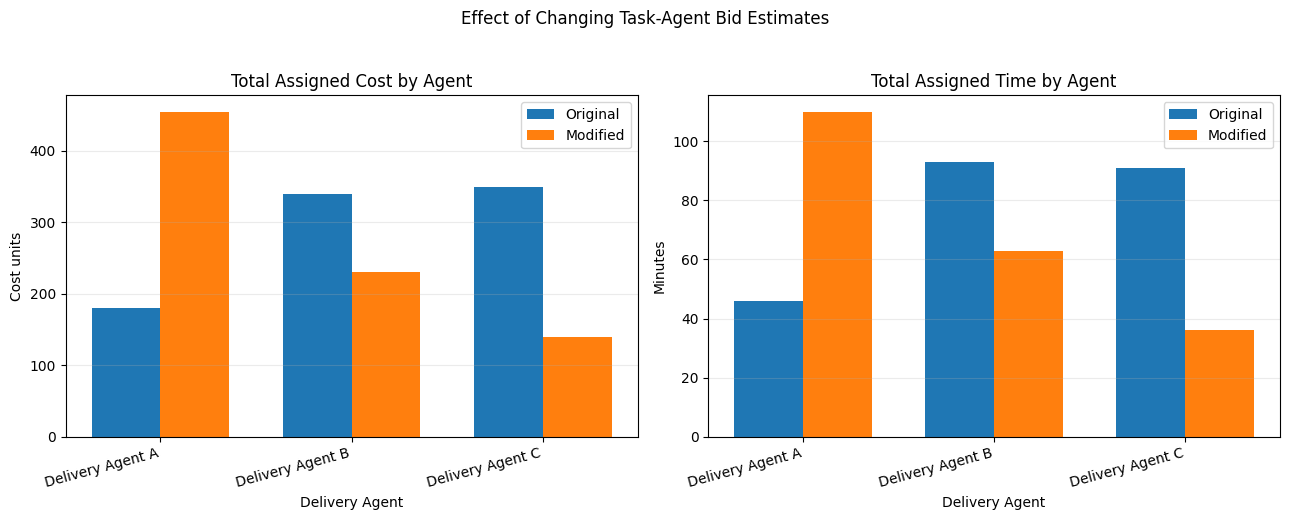

In [11]:
# Plot total assigned cost and total assigned time for each agent in the two scenarios.
plot_data = base_agent_summary[["Agent", "Total_Cost", "Total_Time_Minutes"]].merge(
    modified_agent_summary[["Agent", "Total_Cost", "Total_Time_Minutes"]],
    on="Agent", suffixes=("_Original", "_Modified")
)

x = range(len(plot_data))
width = 0.36
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar([i - width / 2 for i in x], plot_data["Total_Cost_Original"], width, label="Original")
axes[0].bar([i + width / 2 for i in x], plot_data["Total_Cost_Modified"], width, label="Modified")
axes[0].set_title("Total Assigned Cost by Agent")
axes[0].set_xlabel("Delivery Agent")
axes[0].set_ylabel("Cost units")
axes[0].set_xticks(list(x), plot_data["Agent"], rotation=15, ha="right")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar([i - width / 2 for i in x], plot_data["Total_Time_Minutes_Original"], width, label="Original")
axes[1].bar([i + width / 2 for i in x], plot_data["Total_Time_Minutes_Modified"], width, label="Modified")
axes[1].set_title("Total Assigned Time by Agent")
axes[1].set_xlabel("Delivery Agent")
axes[1].set_ylabel("Minutes")
axes[1].set_xticks(list(x), plot_data["Agent"], rotation=15, ha="right")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.25)

plt.suptitle("Effect of Changing Task-Agent Bid Estimates", y=1.03)
plt.tight_layout()
plt.show()

## 8. Observations and conclusion

1. **Agent setup:** One Manager Agent coordinates three Delivery Agents. Eight delivery tasks are available, and each agent provides its own cost and time estimate for every task.
2. **PGP coordination:** The initial local plans contained a simultaneous shared-resource/location conflict. Revising one plan to a free time slot removed the conflict from the combined plan.
3. **CNP:** Each task passed through announcement, bid submission, bid comparison, agent selection, and assignment. The manager selected the lowest-scoring offer under the chosen score rule.
4. **Multiple allocation:** The notebook automatically assigned all eight tasks and calculated total cost, total assigned time, and estimated parallel completion time.
5. **Modification:** Changing selected bids changed the winning agents for some tasks. The summary tables and bar charts show how the allocation affects the cost and time carried by each agent.

**Conclusion:** PGP helps coordinate local plans when agents' intended use of a shared place or resource conflicts. CNP provides a structured way for a manager to announce tasks, collect offers, compare bids, and award tasks. The final allocation depends on the input estimates and the bid-comparison rule.